5번째 코드

pretrained model FER 가중치 채용 + 재웅님 증강 데이터 추가학습
--> feaedback1: neutral 데이터가 애초에 너무 적고, 모델에 의한 분류가 아닌 사람이 직접 지정한 분류이므로
pretrained model이 판별하는 neutral data와는 거리가 있음. --> train 데이터는 95%까지 나오는데, val 데이터는 70%대.

=== 추가 수정사항 ===
1) neutral vs 4감정 이진분류를 1차 필터로 두고, 그 다음 4감정 분류
2) neutral 증강데이터 대폭 증가(기존보다 몇배 더 늘리기)
3) neutral의 loss weight를 대폭 높여서 가중치 조정(개인적인 예상인데, 4감정의 분류 기준에도 영향을 줄 가능성도 있을 것 같음)

In [2]:
# 환경 설정 및 라이브러리 임포트
import os
import json
import cv2
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
import random

# ================= 설정 =================
# 1. 원본 데이터 및 라벨 경로 (dataset_v2)
RAW_IMG_BASE = "/workspace/user1/dataset_v2/img/train" # JSON의 bbox를 사용하기 위한 원본
LBL_BASE = "/workspace/user1/dataset_v2/label_mod/train"
NPZ_BASE = "/workspace/user1/dataset_v2/segmentation/train"

# 2. 팀원이 제공한 증강 데이터 경로 (dataset_v3_augmented)
AUG_IMG_BASE = "/workspace/user5/img_augmented/train"

# 3. 모델 저장 경로
SAVE_DIR = '/workspace/user1/model_v3'
os.makedirs(SAVE_DIR, exist_ok=True)

# 4. 하이퍼파라미터 및 설정
SEED = 42
BATCH_SIZE = 128 # A40 절반 자원 고려
IMG_SIZE = 224
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 5. 감정 라벨 맵
# 원본 'blank' -> 'neutral'로 통합
EMOTION_MAP = {
    'anger': 0, 'happy': 1, 'panic': 2, 'sadness': 3, 'neutral': 4,
    'blank': 4 # 팀원 데이터의 blank 처리
}
CLASS_NAMES = ['anger', 'happy', 'panic', 'sadness', 'neutral']

# 재현성을 위한 시드 고정
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"✅ 환경 설정 완료. 장치: {DEVICE}")

✅ 환경 설정 완료. 장치: cuda


In [3]:
# 통합 데이터셋 클래스 정의 (얼굴 크롭 로직 포함)

class IntegratedEmotionDataset(Dataset):
    def __init__(self, raw_img_base, aug_img_base, lbl_base, npz_base, transform=None):
        self.transform = transform
        self.samples = []
        self.npz_cache = {}

        # ══════════════════════════════════════════════════════════════
        # 소스 1: 원본 데이터셋 (dataset_v2) - 실시간 크롭 필요
        # ══════════════════════════════════════════════════════════════
        print("🔍 소스 1 (원본 + JSON) 로딩 중...")
        if os.path.exists(lbl_base):
            for json_file in tqdm(os.listdir(lbl_base), desc="Loading JSONs"):
                if not json_file.endswith('.json'): continue
                
                with open(os.path.join(lbl_base, json_file), 'r', encoding='utf-8') as f:
                    data = json.load(f)
                    for item in data['images']:
                        # BBox 이상 데이터 제외
                        if item.get('is_box_issue') == 'Yes': continue
                        
                        # 데이터 경로 정보 저장 (실시간 크롭용)
                        self.samples.append({
                            'source': 'raw',
                            'img_path': os.path.join(raw_img_base, item['final_emotion'], item['filename']),
                            'mask_key': f"{item['split']}_{item['original_emotion']}.npz",
                            'mask_filename': item['filename'] + ".npy",
                            'bbox': item['bbox'], # 얼굴 위치 확인용
                            'label': EMOTION_MAP[item['final_emotion']]
                        })

        # ══════════════════════════════════════════════════════════════
        # 소스 2: 팀원 증강 데이터셋 (img_augmented) - 바로 사용 가능
        # ══════════════════════════════════════════════════════════════
        print("\n🔍 소스 2 (팀원 증강데이터) 로딩 중...")
        if os.path.exists(aug_img_base):
            for emotion_folder in EMOTION_MAP.keys(): # {anger, blank, ...}
                src_folder = os.path.join(aug_img_base, emotion_folder)
                if not os.path.isdir(src_folder): continue
                
                label = EMOTION_MAP[emotion_folder] # blank -> neutral 자동 변환
                file_list = [f for f in os.listdir(src_folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
                
                for filename in tqdm(file_list, desc=f"Loading {emotion_folder}", leave=False):
                    self.samples.append({
                        'source': 'aug',
                        'img_path': os.path.join(src_folder, filename),
                        'label': label
                    })
        
        print(f"\n✅ 로딩 완료. 전체 데이터 수: {len(self.samples)}장")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        item = self.samples[idx]
        
        # 1. 원본 소스인 경우 (얼굴위치 확인 -> 크롭 필요)
        if item['source'] == 'raw':
            image = cv2.imread(item['img_path'])
            if image is None: return self.__getitem__(random.randint(0, len(self)-1))
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            
            # --- 얼굴 영역 타이트 크롭 로직 ---
            box = item['bbox']
            x1, y1, x2, y2 = box['minX'], box['minY'], box['maxX'], box['maxY']
            
            # 이미지 경계 처리 (안전장치)
            h, w = image.shape[:2]
            x1, y1 = max(0, x1), max(0, y1)
            x2, y2 = min(w, x2), min(h, y2)
            
            # 유효하지 않은 크롭 영역 예외 처리
            if x2 <= x1 or y2 <= y1: return self.__getitem__(random.randint(0, len(self)-1))
            
            # 크롭 수행
            image = image[y1:y2, x1:x2]
            
        # 2. 증강 소스인 경우 (이미 크롭/가공되어 있으므로 바로 로드)
        else:
            image = cv2.imread(item['img_path'])
            if image is None: return self.__getitem__(random.randint(0, len(self)-1))
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            
        # 3. 공통 증강 및 텐서 변환 (블러 처리는 이 transform 단계에서 수행)
        if self.transform:
            augmented = self.transform(image=image)
            image = augmented['image']
            
        return image, torch.tensor(item['label'], dtype=torch.long)

print("✅ IntegratedEmotionDataset 클래스 정의 완료.")

✅ IntegratedEmotionDataset 클래스 정의 완료.


In [4]:
# 데이터 증강 파이프라인 및 DataLoader 설정

# Train Transform: 팀원 코드를 고려한 실시간 증강 (블러 등 포함)
train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5), # 관객 위치 다양성
    
    # 극장 환경 시뮬레이션 (원본 크롭 데이터의 강건성 확보)
    A.OneOf([
        A.GaussianBlur(blur_limit=(3, 7), p=0.5), # 초점 흐림
        A.MotionBlur(blur_limit=7, p=0.5), # 움직임 흔들림
    ], p=0.3), # 너무 뭉개지지 않게 확률 조절
    
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5), # 스크린 반사광
        A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.5), # 대비 조정
    ], p=0.3),
    
    A.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05, p=0.3), # 피부색 변화
    
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# Validation Transform: 리사이징 및 정규화만 수행 (증강 없음)
val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# 데이터셋 인스턴스 생성 (Train에만 가공 데이터 통합)
train_dataset = IntegratedEmotionDataset(
    RAW_IMG_BASE, AUG_IMG_BASE, LBL_BASE, NPZ_BASE, transform=train_transform
)

# Validation은 이전 Cell 1에서 설정한 원본 데이터셋 세팅을 사용한다고 가정
# (만약 Val 데이터도 새로 구성해야 한다면 IntegratedEmotionDataset의 split 부분을 수정해서 호출해야 함)
# 일단은 이전 단계에서 성공했던 Val 데이터 로직을 그대로 사용한다고 가정하고 경로만 지정.
VAL_IMG_BASE = "/workspace/user1/dataset_v2/img/val"
VAL_LBL_BASE = "/workspace/user1/dataset_v2/label_mod/val"

# (임시) Validation Dataset 정의 (실시간 크롭만 적용된 원본 Val)
class ValRawDataset(Dataset):
    def __init__(self, img_base, lbl_base, transform=None):
        self.transform = transform
        self.samples = []
        if os.path.exists(lbl_base):
            for json_file in os.listdir(lbl_base):
                if not json_file.endswith('.json'): continue
                with open(os.path.join(lbl_base, json_file), 'r', encoding='utf-8') as f:
                    data = json.load(f)
                    for item in data['images']:
                        if item.get('is_box_issue') == 'Yes': continue
                        self.samples.append({
                            'img_path': os.path.join(img_base, item['final_emotion'], item['filename']),
                            'bbox': item['bbox'],
                            'label': EMOTION_MAP[item['final_emotion']]
                        })

    def __len__(self): return len(self.samples)
    def __getitem__(self, idx):
        item = self.samples[idx]
        image = cv2.imread(item['img_path'])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        box = item['bbox']
        image = image[box['minY']:box['maxY'], box['minX']:box['maxX']] # 타이트 크롭
        if self.transform: image = self.transform(image=image)['image']
        return image, torch.tensor(item['label'], dtype=torch.long)

val_dataset = ValRawDataset(VAL_IMG_BASE, VAL_LBL_BASE, transform=val_transform)

# DataLoader 설정 (A40 절반 자원 사용)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print(f"⚡ 데이터 로더 완료. Train: {len(train_dataset)} / Val: {len(val_dataset)}")

🔍 소스 1 (원본 + JSON) 로딩 중...


Loading JSONs: 100%|██████████| 5/5 [00:00<00:00, 25.80it/s]



🔍 소스 2 (팀원 증강데이터) 로딩 중...



✅ 로딩 완료. 전체 데이터 수: 26773장
⚡ 데이터 로더 완료. Train: 26773 / Val: 1163


In [5]:
# 모델 정의 및 학습 설정

import timm

def get_model(num_classes=5):
    # 일반 ImageNet 가중치로 로드
    model = timm.create_model('efficientnet_b2', pretrained=True, num_classes=num_classes)
    
    # 🚨 이전 1번 사본에서 성공했던 FER 전용 가중치 URL (sb-ai-lab)
    fer_url = "https://github.com/sb-ai-lab/EmotiEffLib/raw/main/models/affectnet_emotions/enet_b2_8.pt"
    
    print(f"🚀 FER 전용 가중치 다운로드 및 주입 시도 중...")
    try:
        loaded = torch.hub.load_state_dict_from_url(fer_url, map_location='cpu', weights_only=False)
        
        # 모델 객체가 통째로 온 경우 state_dict만 추출
        if hasattr(loaded, 'state_dict'): loaded = loaded.state_dict()
            
        # 분류 레이어 제외하고 로드
        filtered_dict = {k: v for k, v in loaded.items() if 'classifier' not in k and 'head' not in k and 'fc' not in k}
        model.load_state_dict(filtered_dict, strict=False)
        print(f"✅ FER 전용 사전 학습 가중치 주입 성공!")
    except Exception as e:
        print(f"⚠️ FER 가중치 로드 실패. 일반 가중치로 시작합니다. (사유: {e})")
        
    return model

# 모델, 손실함수, 옵티마이저 설정
model = get_model(num_classes=5).to(DEVICE)

# 'Neutral' 구분을 더 명확히 하기 위해 Label Smoothing 0.05 적용
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

# 전이 학습이므로 안정적인 AdamW 옵티마이저 사용
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)

print("✅ 모델 및 학습 설정 완료.")

🚀 FER 전용 가중치 다운로드 및 주입 시도 중...
✅ FER 전용 사전 학습 가중치 주입 성공!
✅ 모델 및 학습 설정 완료.


In [6]:
# 통합 학습 루프 실행

from tqdm import tqdm

NUM_EPOCHS = 30
PATIENCE = 5
BEST_VAL_LOSS = float('inf')
trigger_times = 0

SAVE_PATH = os.path.join(SAVE_DIR, 'best_integrated_model_fer.pth')

print("🚀 통합 데이터셋 기반 학습 시작...")

for epoch in range(NUM_EPOCHS):
    # --- Train Phase ---
    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0

    train_pbar = tqdm(train_loader, desc=f"Ep [{epoch+1}/{NUM_EPOCHS}] Train")
    for images, labels in train_pbar:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()

        # AMP 적용
        with torch.autocast(device_type='cuda', dtype=torch.float16):
            outputs = model(images)
            loss = criterion(outputs, labels)

        # scaler는 이전 코드에서 가져왔다고 가정 (미정의시 GradScaler 선언 필요)
        if 'scaler' not in globals(): scaler = torch.amp.GradScaler('cuda')
        
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

        train_pbar.set_postfix({'loss': f"{loss.item():.4f}"})

    train_loss = running_loss / len(train_dataset)
    train_acc = correct_train / total_train * 100

    # --- Validation Phase ---
    model.eval()
    val_loss, correct_val, total_val = 0.0, 0, 0

    with torch.no_grad():
        val_pbar = tqdm(val_loader, desc=f"Ep [{epoch+1}/{NUM_EPOCHS}] Val  ")
        for images, labels in val_pbar:
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            with torch.autocast(device_type='cuda', dtype=torch.float16):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_dataset)
    val_acc = correct_val / total_val * 100

    print(f"📊 Train Loss: {train_loss:.4f}, Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f}, Acc: {val_acc:.2f}%")

    # --- Early Stopping & Model Save ---
    if val_loss < BEST_VAL_LOSS:
        BEST_VAL_LOSS = val_loss
        torch.save(model.state_dict(), SAVE_PATH)
        print(f"  💾 성능 개선! 모델 저장됨 (Val Loss: {val_loss:.4f})")
        trigger_times = 0
    else:
        trigger_times += 1
        if trigger_times >= PATIENCE:
            print(f"\n🛑 {PATIENCE} Epoch 동안 개선이 없어 조기 종료합니다.")
            break

print(f"\n✅ 최종 모델 저장 위치: {SAVE_PATH}")

🚀 통합 데이터셋 기반 학습 시작...


Ep [1/30] Train:   0%|          | 0/210 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [1/30] Train:   4%|▍         | 9/210 [00:23<01:55,  1.74it/s, loss=1.9080]  Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [1/30] Train:   8%|▊         | 17/210 [00:39<03:36,  1.12s/it, loss=1.7512]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [1/30] Train:  12%|█▏        | 25/210 [00:55<03:43,  1.21s/it, loss=1.2601]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [1/30] Train:  16%|█▌        | 33/210 [01:11<03:17,  1.12s/it, loss=1.3059]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for se

📊 Train Loss: 1.0918, Acc: 68.48% | Val Loss: 0.7114, Acc: 76.78%
  💾 성능 개선! 모델 저장됨 (Val Loss: 0.7114)


Ep [2/30] Train:   0%|          | 0/210 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/30] Train:   2%|▏         | 4/210 [00:08<04:28,  1.30s/it, loss=0.9041]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/30] Train:   6%|▌         | 12/210 [00:24<03:53,  1.18s/it, loss=1.5581]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/30] Train:   6%|▌         | 13/210 [00:29<08:13,  2.50s/it, loss=0.8469]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/30] Train:  11%|█▏        | 24/210 [00:47<03:54,  1.26s/it, loss=0.8372]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/30] Train:  15%|█▌        | 32/210 [01:03<03:50,  1.29s/it, loss=0.8292]Invalid SOS parameters for sequential J

📊 Train Loss: 0.7101, Acc: 81.37% | Val Loss: 0.7298, Acc: 77.13%


Ep [3/30] Train:   0%|          | 0/210 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [3/30] Train:   6%|▌         | 12/210 [00:25<03:58,  1.20s/it, loss=0.5729]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [3/30] Train:   8%|▊         | 16/210 [00:32<03:40,  1.14s/it, loss=0.5320]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [3/30] Train:  11%|█▏        | 24/210 [00:48<03:25,  1.11s/it, loss=0.4498]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [3/30] Train:  13%|█▎        | 28/210 [00:57<03:34,  1.18s/it, loss=0.4882]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [3/30] Train:  17%|█▋        | 36/210 [01:12<03:10,  1.10s/it, loss=0.

... (3 outputs left out)

Ep [5/30] Train:   0%|          | 0/210 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [5/30] Train:   2%|▏         | 4/210 [00:09<04:31,  1.32s/it, loss=0.3420]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [5/30] Train:   6%|▌         | 12/210 [00:25<04:03,  1.23s/it, loss=0.3196]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [5/30] Train:   8%|▊         | 16/210 [00:33<03:39,  1.13s/it, loss=0.4095]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [5/30] Train:  10%|▉         | 20/210 [00:42<03:58,  1.26s/it, loss=0.4010]Invalid SOS parameters for sequ

📊 Train Loss: 0.3516, Acc: 95.48% | Val Loss: 0.7436, Acc: 76.96%


Ep [6/30] Train:   0%|          | 0/210 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [6/30] Train:   4%|▍         | 8/210 [00:16<03:55,  1.17s/it, loss=0.3603]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [6/30] Train:   6%|▌         | 12/210 [00:23<03:28,  1.05s/it, loss=0.3723]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [6/30] Train:  10%|▉         | 20/210 [00:38<03:20,  1.06s/it, loss=0.3524]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [6/30] Train:  11%|█▏        | 24/210 [00:45<03:37,  1.17s/it, loss=0.3303]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [6/30] Train:  13%|█▎        | 28/210 [00:53<03:34,  1.18s/it, loss=0.3

📊 Train Loss: 0.3424, Acc: 95.86% | Val Loss: 0.7940, Acc: 77.90%

🛑 5 Epoch 동안 개선이 없어 조기 종료합니다.

✅ 최종 모델 저장 위치: /workspace/user1/model_v3/best_integrated_model_fer.pth


🚀 FER 전용 가중치 다운로드 및 주입 시도 중...
✅ FER 전용 사전 학습 가중치 주입 성공!


Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS

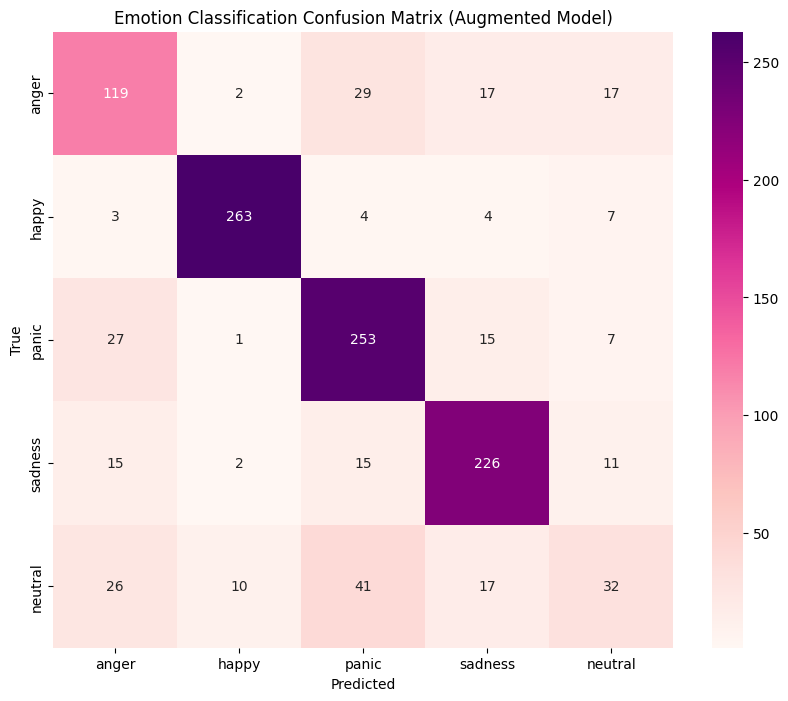

In [7]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 방금 학습한 통합 모델 로드
model = get_model(num_classes=5).to(DEVICE)
model.load_state_dict(torch.load('/workspace/user1/model_v3/best_integrated_model_fer.pth'))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader:
        imgs = imgs.to(DEVICE)
        with torch.autocast(device_type='cuda', dtype=torch.float16):
            out = model(imgs)
        all_preds.extend(torch.max(out, 1)[1].cpu().numpy())
        all_labels.extend(lbls.numpy())

# 혼동 행렬 시각화
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='RdPu', 
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Emotion Classification Confusion Matrix (Augmented Model)')
plt.show()